In [19]:
import numpy as np
rnd_seed = 42
np.random.seed(rnd_seed)


In [20]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('Fashion-MNIST', version=1, as_frame=False)

X = mnist.data
y = mnist.target.astype(int)


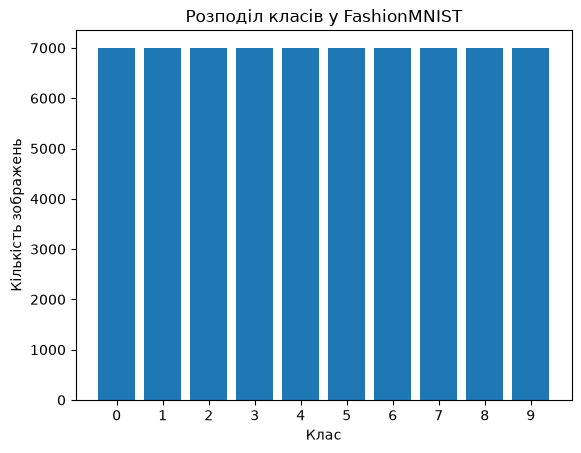

In [21]:
import matplotlib.pyplot as plt

classes, count_cls = np.unique(y, return_counts=True)

plt.bar(classes, count_cls)
plt.xlabel("Клас")
plt.ylabel("Кількість зображень")
plt.title("Розподіл класів у FashionMNIST")
plt.xticks(classes)
plt.show()

Розподіл калсів рівномірний, можна використовувти accuracy

In [ ]:
from sklearn.model_selection import train_test_split

# нормалізація до [0, 1] — фіксоване відображення, витоку немає
X = X.astype(np.float32) / 255.0

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=rnd_seed, stratify=y
)


## Модель і перевірка градієнтів

In [ ]:
from copy import deepcopy

from mlp import MLP
from activations import Relu, SoftMax
from layers import Dense
from losses import CategoricalCrossEntropy
from GD import SGD


def make_model(l1=0.0, l2=0.0, dropout=0.0, weight_clip=None, grad_clip=None, lr=0.01):
    np.random.seed(rnd_seed)
    layers = [
        Dense(784, 256, Relu()),
        Dense(256, 128, Relu()),
        Dense(128, 64, Relu()),
        Dense(64, 10, SoftMax()),
    ]
    return MLP(layers, loss=CategoricalCrossEntropy(), optimizer=SGD(learning_rate=lr),
               l1=l1, l2=l2, dropout_probs=[dropout] * 3,
               weight_clip=weight_clip, grad_clip=grad_clip)


def hidden_weights(model):
    return np.concatenate([l.W.ravel() for l in model.layers[:-1]])

In [ ]:
import pandas as pd


def gradient_check(model, X, y, n_checks=5, eps=1e-5, seed=0):
    rng = np.random.default_rng(seed)
    X = X.astype(np.float64)

    P = model.forward(X, training=False)
    grads = model.backward(P, y)

    def loss_value():
        return model.loss.forward(model.forward(X, training=False), y)

    rows = []
    for li, layer in enumerate(model.layers):
        for name in ("W", "b"):
            param = getattr(layer, name)
            for _ in range(n_checks):
                pos = tuple(int(rng.integers(0, s)) for s in param.shape)
                old = param[pos]

                param[pos] = old + eps
                l_plus = loss_value()
                param[pos] = old - eps
                l_minus = loss_value()
                param[pos] = old                                   # повертаємо значення

                g_num = (l_plus - l_minus) / (2 * eps)             # формула 27
                g_an = grads[li][name][pos]
                err = abs(g_an - g_num) / max(1e-8, abs(g_an) + abs(g_num))   # формула 28
                rows.append({"параметр": f"{name}{li}{list(pos)}",
                             "analytic": g_an, "numeric": g_num, "rel. error": err})
    return pd.DataFrame(rows)


model_gc = make_model()                      # базова мережа, без регуляризації
idx_gc = np.random.default_rng(rnd_seed).choice(len(X_train), 30, replace=False)
gc = gradient_check(model_gc, X_train[idx_gc], y_train[idx_gc])
display(gc)
print("max rel. error:", gc["rel. error"].max())

,параметр,analytic,numeric,rel. error
0,"W0[666, 163]",0.000000,0.000000,0.000000e+00
1,"W0[400, 69]",-0.000008,-0.000008,3.022732e-08
2,"W0[241, 10]",-0.005343,-0.005343,9.824341e-10
3,"W0[58, 4]",0.000069,0.000069,1.018159e-07
4,"W0[137, 208]",0.000000,0.000000,0.000000e+00
5,"b0[0, 166]",-0.002352,-0.002352,1.117495e-09
6,"b0[0, 233]",0.000000,0.000000,0.000000e+00
7,"b0[0, 128]",-0.007055,-0.007055,6.939806e-10
8,"b0[0, 155]",-0.001534,-0.001534,3.767450e-09
9,"b0[0, 248]",-0.000348,-0.000348,2.300692e-08


max rel. error: 1.0181585826658715e-07


## Експерименти з регуляризацією, дропаутом, обрізанням ваг та градієнтів

In [ ]:
L1_GRID = [1e-4, 1e-3, 1e-2]
L2_GRID = [1e-3, 1e-2, 1e-1]
DROPOUT_GRID = [0.1, 0.3, 0.5]       
WEIGHT_CLIP_GRID = [1.0, 0.1]              
GRAD_CLIP_GRID = [0.1, 1.0, 5.0]
COMBINED_L2_GRID = [1e-3, 1e-2]


configs = {"baseline": ("Без регуляризації", "—", {})}
for v in L1_GRID:
    configs[f"L1 λ1={v:g}"] = ("L1", f"λ1={v:g}", dict(l1=v))
for v in L2_GRID:
    configs[f"L2 λ2={v:g}"] = ("L2", f"λ2={v:g}", dict(l2=v))
for p in DROPOUT_GRID:
    configs[f"Dropout {p:g}"] = ("Dropout", f"p={p:g}", dict(dropout=p))
for c in WEIGHT_CLIP_GRID:
    configs[f"Weight clip ±{c:g}"] = ("Weight clipping", f"±{c:g}", dict(weight_clip=c))
for c in GRAD_CLIP_GRID:
    configs[f"Grad clip c={c:g}"] = ("Gradient clipping", f"c={c:g}", dict(grad_clip=c))
for v in COMBINED_L2_GRID:
    configs[f"L2 + Dropout 0.2, λ2={v:g}"] = ("L2 + Dropout 0.2", f"λ2={v:g}, p=0.2", dict(l2=v, dropout=0.2))

models = {name: make_model(**kw) for name, (_, _, kw) in configs.items()}
models_he = deepcopy(models)          
print(len(models), "експериментів")

17 експериментів


In [ ]:
import os
from joblib import Parallel, delayed, parallel_config

EPOCHS = 20
BATCH_SIZE = 128


def run_experiment(name, model, X_tr, y_tr, X_v, y_v, epochs, batch_size):
    np.random.seed(rnd_seed)
    model = deepcopy(model)
    model.fit(X_tr, y_tr, epochs=epochs, batch_size=batch_size, X_val=X_v, y_val=y_v)

    sp_layers, sp_total = model.sparsity()
    clip = model.weight_clip
    row = {
        "dead neurons": model.dead_neurons(X_tr),          
        "sparsity": sp_total,                              
        "sparsity_layers": sp_layers,
        "train acc": model.history["train_acc"][-1],
        "valid acc": model.history["val_acc"][-1],
        "valid CE": model.history["val_ce"][-1],
        "at bounds": None if clip is None else int(np.sum(np.abs(hidden_weights(model)) >= clip)),
    }
    return name, model, row


n_jobs = min(len(models), os.cpu_count())
with parallel_config(backend="loky", inner_max_num_threads=1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(run_experiment)(name, m, X_train, y_train, X_val, y_val, EPOCHS, BATCH_SIZE)
        for name, m in models.items()
    )

models = {name: m for name, m, _ in results}
res_table = {name: row for name, _, row in results}

## Порівняльна таблиця

In [ ]:
df = pd.DataFrame.from_dict(res_table, orient="index")
df["dead_mean"] = df["dead neurons"].apply(np.mean)
df["at bounds"] = df["at bounds"].astype("Int64")
df.insert(0, "Метод", [configs[n][0] for n in df.index])
df.insert(1, "Параметри", [configs[n][1] for n in df.index])

results_table = df[["Метод", "Параметри", "dead_mean", "sparsity", "train acc", "valid acc", "valid CE"]].rename(
    columns={"dead_mean": "Dead neurons, %", "sparsity": "Sparsity, %", "train acc": "Train accuracy",
             "valid acc": "Val. accuracy", "valid CE": "Val. loss"}
).round(4)
results_table

,Метод,Параметри,"Dead neurons, %","Sparsity, %",Train accuracy,Val. accuracy,Val. loss
baseline,Без регуляризації,—,1.5625,14.2891,0.8745,0.8628,0.3833
L1 λ1=0.0001,L1,λ1=0.0001,1.5625,26.1952,0.8712,0.8595,0.3899
L1 λ1=0.001,L1,λ1=0.001,5.2083,87.7253,0.8348,0.8266,0.5117
L1 λ1=0.01,L1,λ1=0.01,21.3542,99.8762,0.6583,0.6574,0.9551
L2 λ2=0.001,L2,λ2=0.001,1.5625,15.5260,0.8714,0.8599,0.3889
L2 λ2=0.01,L2,λ2=0.01,4.9479,31.7931,0.8532,0.8434,0.4542
L2 λ2=0.1,L2,λ2=0.1,13.8021,92.0740,0.7152,0.7104,0.9847
Dropout 0.1,Dropout,p=0.1,0.0000,14.3328,0.8734,0.8641,0.3789
Dropout 0.3,Dropout,p=0.3,0.0000,14.3580,0.8590,0.8511,0.4104
Dropout 0.5,Dropout,p=0.5,0.0000,14.3456,0.8344,0.8289,0.4764


Sparsity при всіх дропаутах майже така сама, як у baseline (14.33/14.36/14.35 % проти 14.29 %), тобто dropout не змінює розподіл ваг і не робить модель розрідженою. Збільшення p не обов'язково покращує якість, бо навчання сповільнюється: при p=0.5 train accuracy лише 0.8344 і val loss 0.4764 проти 0.3833 у baseline, а за 20 епох модель не встигає вийти на плато. Перенавчання в baseline майже немає (0.8745 проти 0.8628), тому пригнічувати нема чого, і сильний dropout лише забирає ємність моделі.

Weight clipping при ±1 дає результати, ідентичні baseline за всіма метриками (1.5625 % мертвих, sparsity 14.2891 %, accuracy 0.8745/0.8628, val loss 0.3833): жодна вага не досягає межі, тому обмеження ніяк не спрацьовує. При ±0.1 точність помітно падає (0.8381/0.8311, val loss 0.4731), мертвих нейронів трохи більше (2.6042 %), а sparsity майже не змінюється (14.1005 %): жорстка межа не робить ваги нульовими, вона лише не дозволяє їм бути великими.

Gradient clipping залежить від порога. При c=5 результати практично збігаються з baseline (0.8748/0.8626, val loss 0.3833, 1.5625 %, sparsity 14.2837 %), бо поріг майже не спрацьовує. При c=1 точність трохи нижча (0.8636/0.8557, val loss 0.4139), а мертвих нейронів більше (3.3854 %). При c=0.1 навчання сильно сповільнюється: 0.8037/0.7946, val loss 0.6226, при цьому мертвих нейронів стільки ж, як у baseline (1.5625 %), тобто падіння точності тут не пов'язане з мертвими нейронами. Sparsity при всіх порогах лишається 14.28–14.40 %, оскільки gradient clipping обмежує градієнти, а не ваги.

Комбінація L2 + Dropout 0.2 при λ2=0.001 дає 0.8651/0.8575 (val loss 0.3964): це близько до L2 λ2=0.001 окремо (0.8599) і лежить між Dropout 0.1 (0.8641) та Dropout 0.3 (0.8511), тобто виграшу в точності немає. Мертвих нейронів немає зовсім (0 % проти 1.5625 % у L2 окремо), sparsity майже така сама (15.6093 % проти 15.5260 %). При λ2=0.01 комбінація гірша і за L2 окремо, і за Dropout 0.3 (0.8427/0.8358 проти 0.8532/0.8434 та 0.8590/0.8511, val loss 0.4683): методи накладаються, модель стає надмірно обмеженою. Мертвих нейронів при цьому значно менше, ніж у L2 окремо (0.5208 % проти 4.9479 %), а sparsity лишається такою самою (31.8872 % проти 31.7931 %), бо її визначає L2. Отже, синергії за точністю немає, dropout лише зменшує кількість мертвих нейронів.

Загалом найкращі показники в baseline, Dropout 0.1 та тих методів, що практично не змінюють модель (L1 λ1=0.0001, L2 λ2=0.001, weight clip ±1, grad clip c=5); різниці між ними (до ~0.3 %) лежать у межах шуму. Усі сильніші регуляризації знижують точність, але змінюють властивості моделі: L1/L2 підвищують sparsity, а dropout прибирає мертві нейрони.

In [28]:
# мертві нейрони по кожному прихованому шару (на всій тренувальній вибірці, inference)
dead_layers = pd.DataFrame(df["dead neurons"].tolist(), index=df.index,
                           columns=["Шар 1 (256), %", "Шар 2 (128), %", "Шар 3 (64), %"]).round(2)
dead_layers

,"Шар 1 (256), %","Шар 2 (128), %","Шар 3 (64), %"
baseline,0.00,0.00,4.69
L1 λ1=0.0001,0.00,0.00,4.69
L1 λ1=0.001,0.00,1.56,14.06
L1 λ1=0.01,17.97,24.22,21.88
L2 λ2=0.001,0.00,0.00,4.69
L2 λ2=0.01,0.00,2.34,12.50
L2 λ2=0.1,9.38,13.28,18.75
Dropout 0.1,0.00,0.00,0.00
Dropout 0.3,0.00,0.00,0.00
Dropout 0.5,0.00,0.00,0.00


**Мертві нейрони по шарах.** Частка мертвих нейронів зменшується в бік початку мережі: у baseline 0 / 0 / 4.69 % для шарів 1–3, у L2 λ₂=0.01 — 0 / 2.34 / 12.50 %, у L2 λ₂=0.1 — 9.38 / 13.28 / 18.75 %. Виняток — L1 λ₁=0.01 (17.97 / 24.22 / 21.88 %): за такої сили штрафу мертвими стають нейрони всіх шарів, і максимум припадає на другий.

Dropout (усі p) та L2 + Dropout при λ₂=0.001 дають 0 % мертвих нейронів, причому діагностика виконувалась без dropout. Можливе пояснення — випадкове вимкнення сусідів не дає нейрону покладатися на фіксований набір входів, але це припущення, яке тут не перевірялось.

Шари мають різний розмір, тому відсотки порівнюються обережно: один нейрон — це 0.39 % першого шару (256), 0.78 % другого (128) і 1.56 % третього (64). Тобто 4.69 % у третьому шарі baseline — це лише 3 нейрони з 64.

In [29]:
# розрідженість ваг (|W| < 0.01) по шарах, %
sparsity_layers = pd.DataFrame(df["sparsity_layers"].tolist(), index=df.index,
                               columns=["Шар 1", "Шар 2", "Шар 3", "Вихідний шар"])
sparsity_layers["Загалом"] = df["sparsity"]
sparsity_layers.round(2)

,Шар 1,Шар 2,Шар 3,Вихідний шар,Загалом
baseline,15.61,8.47,6.02,3.12,14.29
L1 λ1=0.0001,28.57,15.97,10.49,5.16,26.20
L1 λ1=0.001,92.37,69.61,51.17,27.81,87.73
L1 λ1=0.01,99.89,99.95,99.69,94.84,99.88
L2 λ2=0.001,16.97,9.19,6.46,2.97,15.53
L2 λ2=0.01,34.67,19.43,12.79,6.41,31.79
L2 λ2=0.1,95.20,79.45,70.47,34.69,92.07
Dropout 0.1,15.63,8.67,6.04,2.97,14.33
Dropout 0.3,15.63,8.72,6.56,3.28,14.36
Dropout 0.5,15.64,8.68,6.08,3.91,14.35


**Розрідженість по шарах.** Розрідженість збільшується в бік початку мережі: у baseline 15.61 / 8.47 / 6.02 / 3.12 % (шари 1–3 та вихідний). Цей порядок зберігається в усіх експериментах, окрім L1 λ₁=0.01, де майже всі ваги вже нульові.

Здебільшого це наслідок ініціалізації. При He std = √(2/n_in), тобто 0.050 для шару 784→256, 0.088 для 256→128, 0.125 для 128→64 і 0.177 для 64→10. Частка нормально розподілених ваг із |w| < 0.01 для таких σ становить приблизно 15.8 / 9.0 / 6.4 / 4.5 %, що майже збігається з baseline. Тобто без регуляризації SGD мало відводить ваги від початкового розподілу, і розрідженість baseline — це в основному розрідженість He-ініціалізації. Регуляризація цей порядок підсилює: чим ширший вхід шару (менші початкові ваги), тим більша частка ваг потрапляє під поріг (L1 λ₁=0.001: 92 / 70 / 51 / 28 %).

Звідси: метрика |w| < 0.01 залежить від масштабу ваг шару, а не лише від сили регуляризації.

In [30]:
# weight clipping: скільки ваг прихованих шарів дійшло до меж
df.loc[df["Метод"] == "Weight clipping", ["Параметри", "at bounds", "sparsity", "dead_mean", "valid acc"]]

,Параметри,at bounds,sparsity,dead_mean,valid acc
Weight clip ±1,±1,0,14.289075,1.562500,0.862786
Weight clip ±0.1,±0.1,1552,14.100469,2.604167,0.831071


**Weight clipping: ваги на межах.** При c=1 жодна вага не досягає межі, тому результат повністю збігається з baseline (sparsity 14.2891 %, val accuracy 0.8628): межа ±1 неактивна, і цей експеримент нічого не обмежує. При c=0.1 точно на межі стоїть лише 1552 ваги з 241 664 (0.64 %), але це лише нижня оцінка: гістограма нижче показує значно більшу концентрацію ваг поруч із межами.

## Графіки навчання

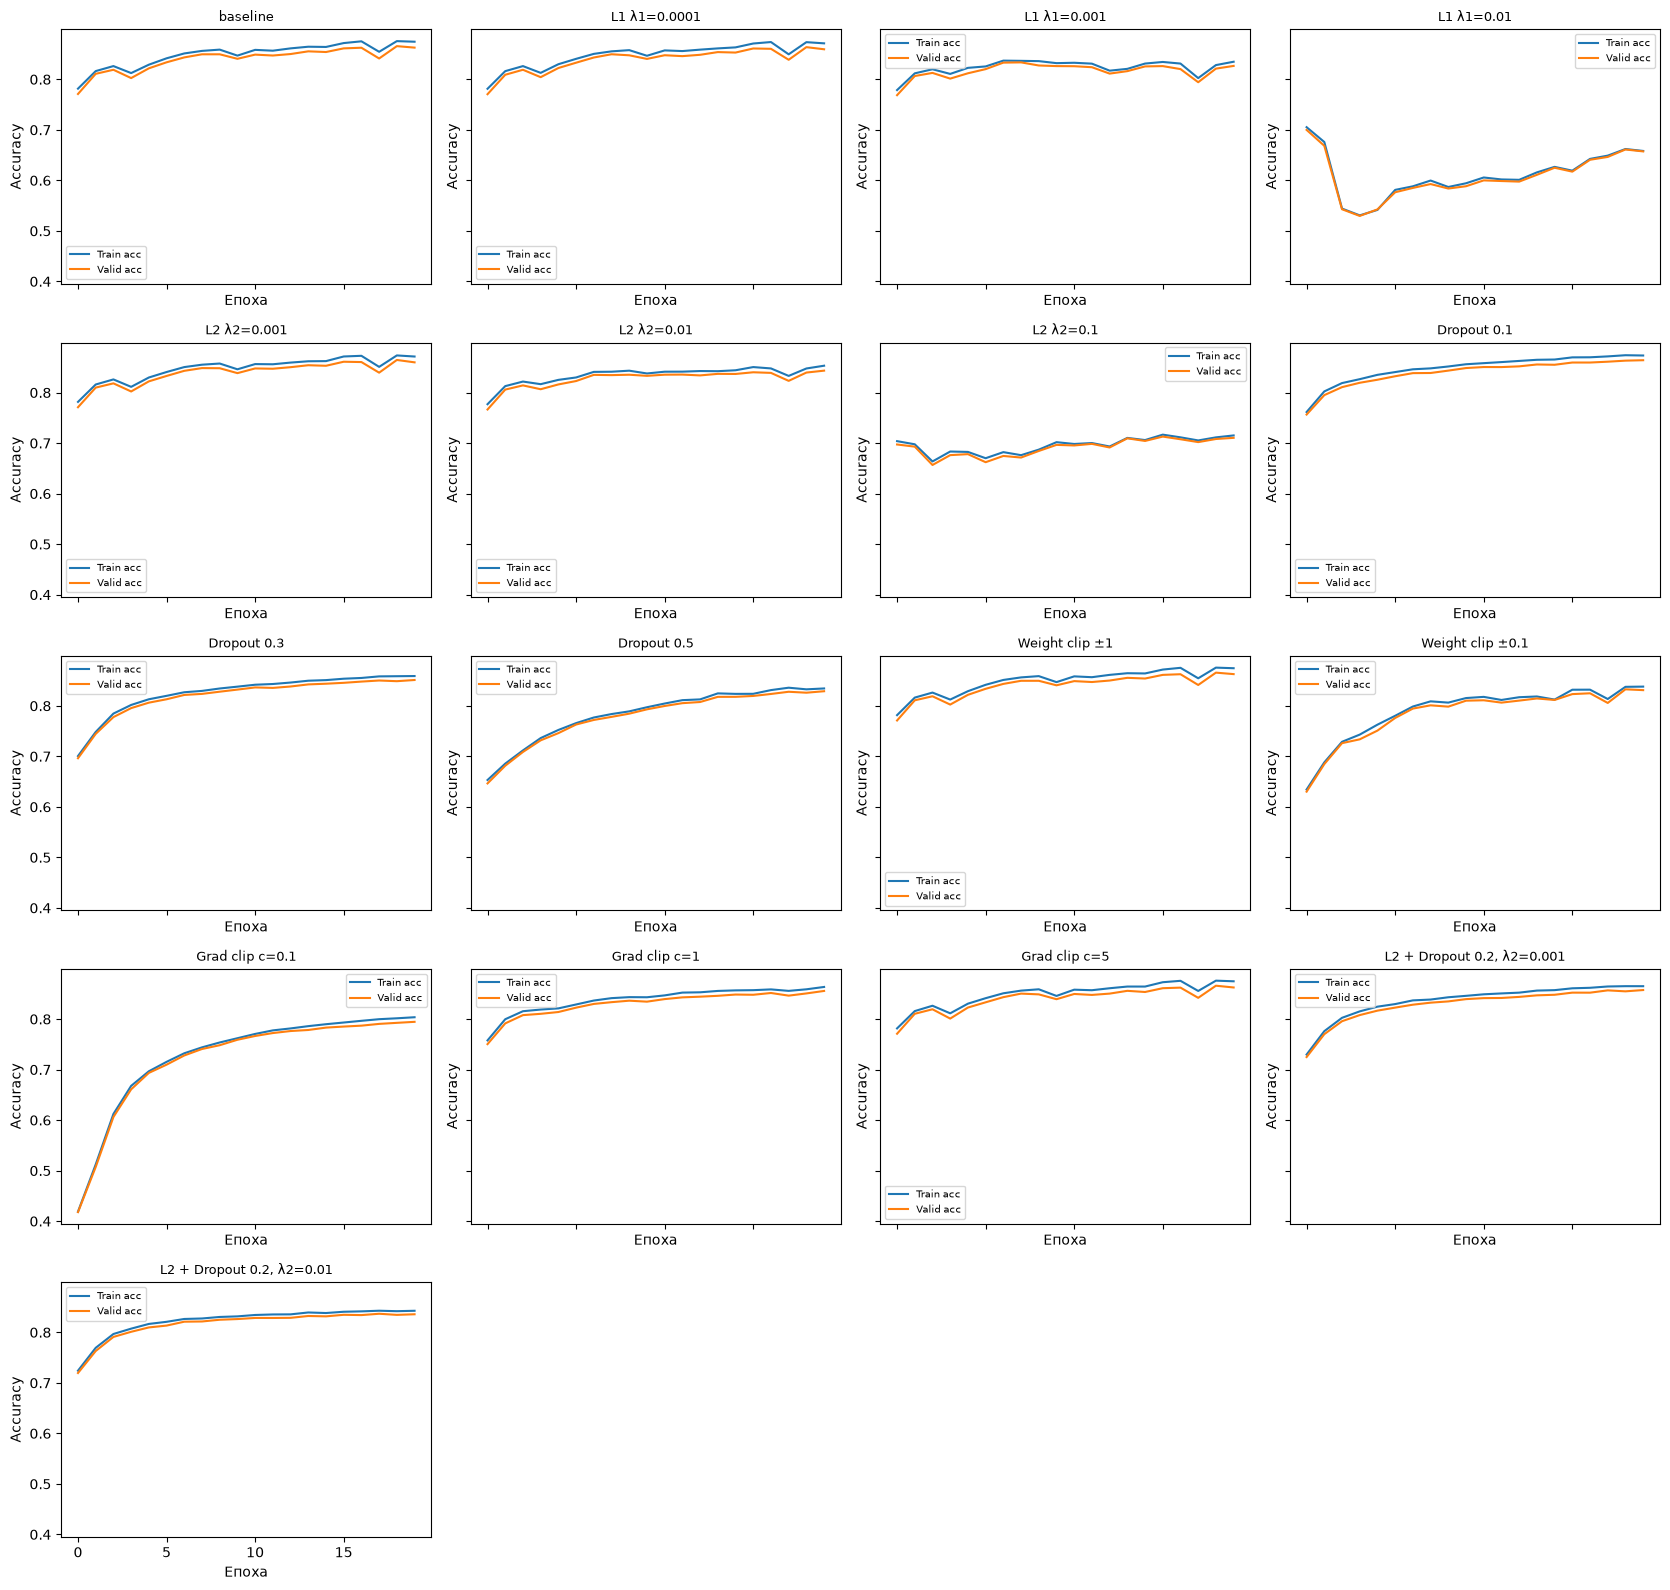

In [31]:
def make_grid(n, ncols=4, w=4.2, h=3.2, **kw):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows), **kw)
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis("off")
    return fig, axes[:n]


fig, axes = make_grid(len(models), sharex=True, sharey=True)
for ax, name in zip(axes, models):
    ax.plot(models[name].history["train_acc"], label="Train acc")
    ax.plot(models[name].history["val_acc"], label="Valid acc")
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Епоха")
    ax.set_ylabel("Accuracy")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

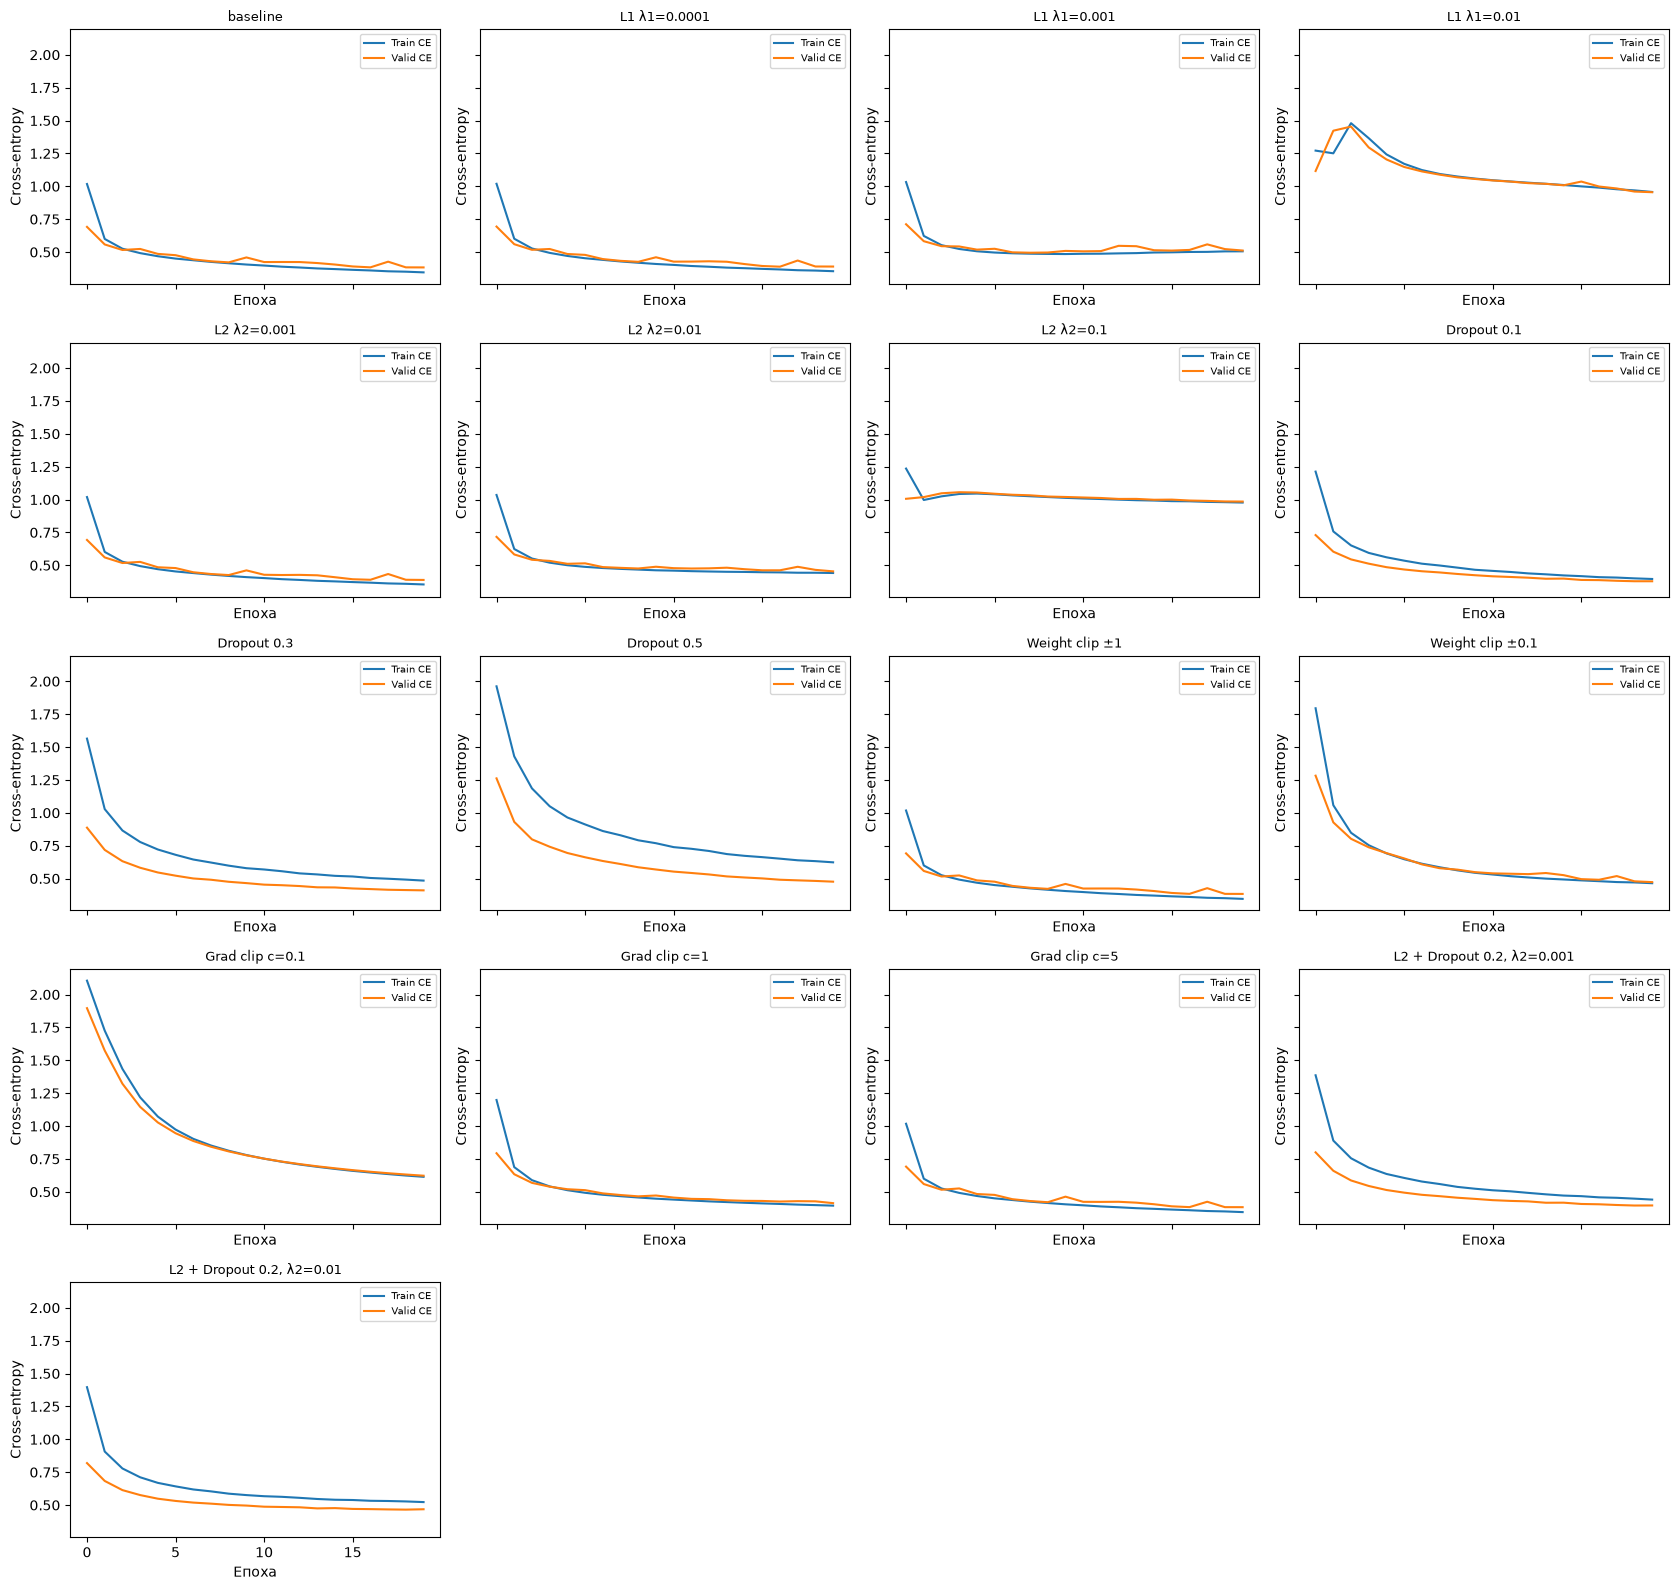

In [32]:
fig, axes = make_grid(len(models), sharex=True, sharey=True)
for ax, name in zip(axes, models):
    ax.plot(models[name].history["train_ce"], label="Train CE")
    ax.plot(models[name].history["val_ce"], label="Valid CE")
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Епоха")
    ax.set_ylabel("Cross-entropy")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

**Криві навчання.**

*Без регуляризації та зі слабкою* (baseline, L1 λ₁=1e-4, L2 λ₂=1e-3, weight clip ±1, grad clip c=5) криві практично збігаються, а відмінності в таблиці не перевищують 0.5 %. На графіку accuracy в них видно «зубці» — локальні провали. Розрив між train і val малий (baseline 0.8745 проти 0.8628): суттєвого перенавчання за 20 епох немає, тож регуляризації майже нічого виправляти.

*Сильна регуляризація сповільнює навчання або обвалює його.* При L1 λ₁=0.01 accuracy на перших епохах падає з ≈0.70 до ≈0.53, CE спочатку зростає, і модель лише повільно відновлюється (0.657 наприкінці). При L2 λ₂=0.1 accuracy майже не росте (≈0.66–0.71), CE тримається біля 1.0. Це недонавчання. L1 λ₁=0.001 і L2 λ₂=0.01 навчаються, але виходять на плато нижче baseline.

*Dropout* робить криві гладкими й монотонними, «зубців» немає. Чим більше p, тим повільніше навчання: на 20-й епосі val accuracy 0.864 / 0.851 / 0.829 для p=0.1 / 0.3 / 0.5, і крива не встигає вийти на плато. Train CE у dropout-моделей вища за val CE, імовірно через шум від випадкового вимкнення нейронів під час навчання.

*Gradient clipping при c=1* теж прибирає «зубці» й дає гладку криву, хоча фінальна точність трохи нижча (0.856 проти 0.863). Імовірне пояснення: обрізання зменшує кроки на батчах із великим градієнтом, які й дають стрибки. При c=5 поріг майже не спрацьовує, тому криві збігаються з baseline. При c=0.1 кроки надто малі: навчання стартує з accuracy ≈0.42 і до 20-ї епохи не виходить на плато (0.795).

*L2 + Dropout* поєднує ефекти обох методів: гладкі криві (від dropout) і нижче плато (від L2). При λ₂=0.001 результат (0.858) лежить між Dropout 0.1 (0.864) і Dropout 0.3 (0.851), тобто L2 майже нічого не додає. При λ₂=0.01 (0.836) гірше і за L2 окремо (0.843), і за Dropout 0.3 (0.851): обмеження накладаються, модель стає надмірно обмеженою, тож синергії за точністю немає. Мертвих нейронів при цьому менше, ніж у L2 окремо (0 % проти 1.56 % та 0.52 % проти 4.95 %), а sparsity практично та сама (15.61 проти 15.53 % та 31.89 проти 31.79 %), бо її визначає L2. Окремого запуску Dropout з p=0.2 немає, тому порівняння виконано з p=0.1 і 0.3.

## Розподіл ваг прихованих шарів

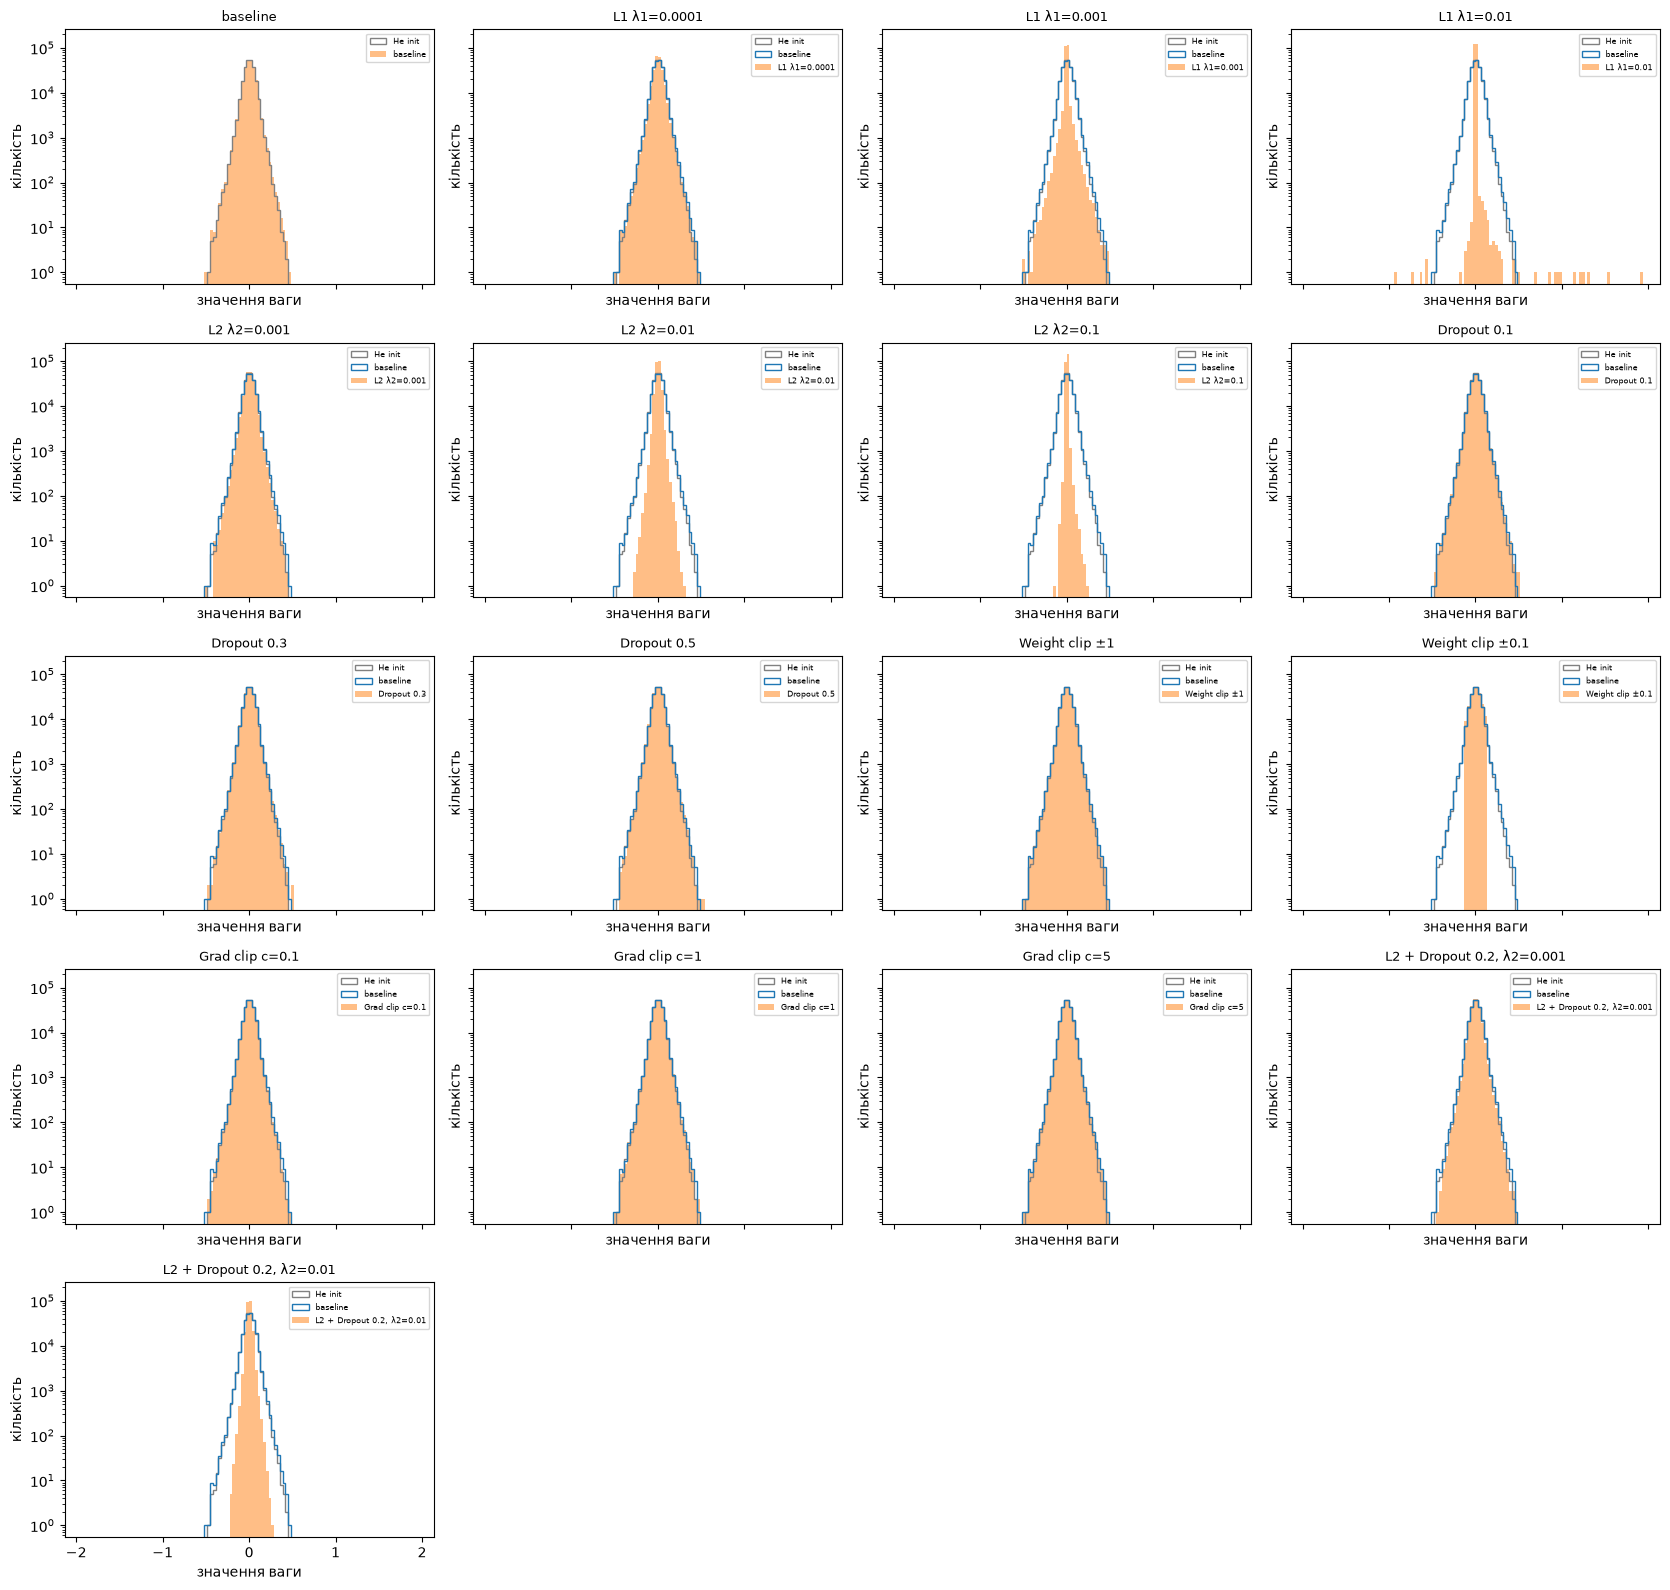

In [33]:
w_base = hidden_weights(models["baseline"])

lim = max(np.abs(hidden_weights(m)).max() for m in list(models.values()) + list(models_he.values()))
bins = np.linspace(-lim, lim, 121)

fig, axes = make_grid(len(models), sharex=True, sharey=True)
for ax, name in zip(axes, models):
    ax.hist(hidden_weights(models_he[name]), bins=bins, histtype="step", color="gray", label="He init")
    if name != "baseline":
        ax.hist(w_base, bins=bins, histtype="step", color="tab:blue", label="baseline")
    ax.hist(hidden_weights(models[name]), bins=bins, alpha=0.5, color="tab:orange", label=name)
    ax.set_yscale("log")
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("значення ваги")
    ax.set_ylabel("кількість")
    ax.legend(fontsize=6)
plt.tight_layout()
plt.show()

**Розподіл ваг** (гістограми в логарифмічному масштабі; сірий — He-ініціалізація, синій — baseline).

Baseline майже збігається з початковим розподілом: без регуляризації ваги за 20 епох мало відходять від ініціалізації.

L1 і L2 змінюють форму розподілу: звужують його й підвищують пік біля нуля. Розподіл лишається симетричним відносно нуля, бо обидва штрафи однаково діють на ваги обох знаків, тож змінюються ширина й гострота піку, а не асиметрія.

Різниця L1 і L2 — у хвостах. L2 тягне вагу до нуля пропорційно до її величини (λ₂w), тому найсильніше скорочує великі ваги, і розподіл стає вузьким дзвоном без хвостів (L2 λ₂=0.1). L1 тягне кожну вагу з однаковою силою λ₁ незалежно від величини: малі ваги доходять до нуля (гострий пік), а окремі потрібні моделі ваги лишаються великими. На L1 λ₁=0.01 видно поодинокі ваги порядку 1–2 за модулем, далеко від центру (у baseline максимум ≈0.5), чого в жодному L2-експерименті немає.

Dropout і gradient clipping практично не змінюють розподіл: гістограми Dropout 0.1/0.3/0.5, Grad clip c=1 і c=5 збігаються з baseline (sparsity 14.33–14.36 % проти 14.29 %). Єдиний помітний слід — вихідний шар при Grad clip c=0.1 (sparsity 5.00 % проти 3.12 %). Ці методи впливають на траєкторію оптимізації, але не штрафують і не обмежують самі ваги.

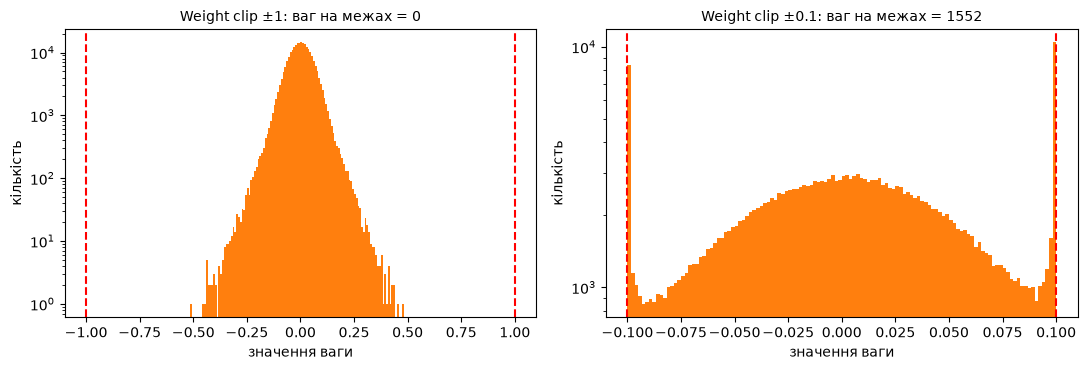

In [34]:
# weight clipping: чи є піки біля меж
clip_names = [n for n in models if configs[n][0] == "Weight clipping"]
fig, axes = plt.subplots(1, len(clip_names), figsize=(5.5 * len(clip_names), 3.8), squeeze=False)
for ax, name in zip(axes.ravel(), clip_names):
    c = models[name].weight_clip
    w = hidden_weights(models[name])
    ax.hist(w, bins=120, color="tab:orange")
    ax.axvline(-c, color="red", ls="--")
    ax.axvline(c, color="red", ls="--")
    ax.set_yscale("log")
    ax.set_title(f"{name}: ваг на межах = {int(np.sum(np.abs(w) >= c))}", fontsize=10)
    ax.set_xlabel("значення ваги")
    ax.set_ylabel("кількість")
plt.tight_layout()
plt.show()

**Weight clipping.** При c=1 розподіл не зачеплений межами: ваги лежать приблизно в (−0.5, 0.5), поруч із межами порожньо. При c=0.1 розподіл обрізається по краях: біля ±0.1 з'являються гострі піки порядку 10⁴ ваг у крайніх бінах. Це механіка методу: усе, що виходить за межу, замінюється значенням межі. Піки значно вищі за точне число ваг на межі (1552), бо решта ваг стоїть поруч із нею, у межах ширини біну (≈0.0017).

Піки такі великі, бо c=0.1 урізає вже саму ініціалізацію: при He-std 0.050 / 0.088 / 0.125 для шарів 1–3 за нормальним розподілом приблизно 2·10⁴ початкових ваг лежать за межами ±0.1 (це оцінка, а не підрахунок) і зрізаються на першому ж кроці. Жорстка межа не дає моделі використовувати великі ваги й шукати оптимальні значення за її межами, тому val accuracy падає до 0.831 (при c=1 — 0.863), хоча розрідженість майже не змінюється (14.10 %).

## Мертві нейрони і validation accuracy

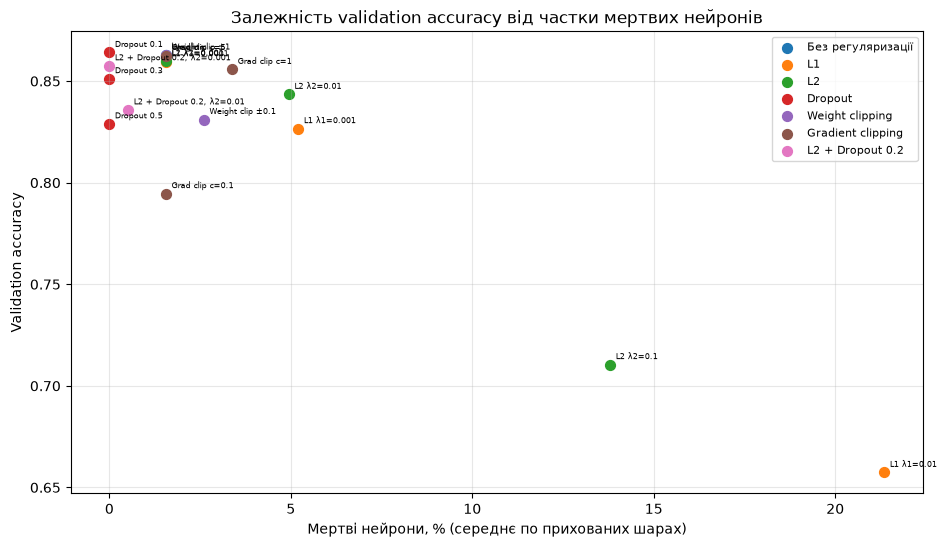

In [35]:
fig, ax = plt.subplots(figsize=(11, 6))
cmap = plt.get_cmap("tab10")
for gi, g in enumerate(df["Метод"].unique()):
    sub = df[df["Метод"] == g]
    ax.scatter(sub["dead_mean"], sub["valid acc"], color=cmap(gi), label=g, s=50)

for name, row in df.iterrows():
    ax.annotate(name, (row["dead_mean"], row["valid acc"]),
                textcoords="offset points", xytext=(4, 4), fontsize=6)

ax.set_xlabel("Мертві нейрони, % (середнє по прихованих шарах)")
ax.set_ylabel("Validation accuracy")
ax.set_title("Залежність validation accuracy від частки мертвих нейронів")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.show()

**Мертві нейрони та validation accuracy.**

1. Загальна тенденція спадна, але тримається лише на двох сильно регуляризованих експериментах: L1 λ₁=0.01 (21.4 % мертвих, accuracy 0.657) і L2 λ₂=0.1 (13.8 %, 0.710). У діапазоні 0–5 % мертвих нейронів точки розкидані від 0.795 до 0.864, тобто там залежності між кількістю мертвих нейронів і точністю немає.
2. Велика кількість мертвих нейронів супроводжується зниженням точності, але, імовірно, не є його причиною: обидва явища дає сильна регуляризація. Цього тут прямо не перевіряли.
3. Однакова кількість мертвих нейронів не означає однакової точності: baseline і Grad clip c=0.1 мають по 1.56 % (0.863 проти 0.795), Dropout 0.1 і Dropout 0.5 — по 0 % (0.864 проти 0.829). У цих випадках точність падає через повільне навчання за 20 епох, що видно на кривих.
4. Баланс між розрідженістю й мертвими нейронами: розрідженість до ≈25–30 % майже безкоштовна (L1 λ₁=1e-4: 26 %, точність 0.860 проти 0.863; L2 λ₂=0.01: 31.8 %, 0.843). Далі точність різко падає (L1 λ₁=0.001: 87.7 %, 0.827; L2 λ₂=0.1: 92 %, 0.710), і одночасно частка мертвих нейронів переходить межу ≈13 %.

Показник «Dead neurons» тут — просте середнє по трьох шарах без урахування їх розміру.

## Збереження і відновлення ваг

In [36]:
trained = models["baseline"]
trained.save_weights("baseline_weights.npz")

restored = make_model()                                   # новий екземпляр з тією самою архітектурою
P_orig = trained.predict_proba(X_val)
print("до завантаження:  max|ΔP| =", np.abs(P_orig - restored.predict_proba(X_val)).max())

restored.load_weights("baseline_weights.npz")
P_rest = restored.predict_proba(X_val)

max_diff = np.abs(P_orig - P_rest).max()
same_classes = np.array_equal(trained.predict(X_val), restored.predict(X_val))
print("після завантаження: max|ΔP| =", max_diff)
print("передбачені класи збігаються:", same_classes)
assert max_diff < 1e-7 and same_classes

до завантаження:  max|ΔP| = 0.9830967806266298
після завантаження: max|ΔP| = 0.0
передбачені класи збігаються: True


## Висновок

Збільшення сили регуляризації не завжди покращує узагальнення. У цьому експерименті жоден метод не дав значущого виграшу над baseline (val accuracy 0.8628): найкращий Dropout 0.1 має 0.8641, і різниця 0.13 % лежить у межах шуму. Причина в тому, що перенавчання майже немає (train 0.8745 проти val 0.8628), тож регуляризації нічого виправляти. Слабка регуляризація (L1 λ₁=1e-4, L2 λ₂=1e-3, Dropout 0.1, weight clip ±1, grad clip c=5) нічого не змінює; середня (L2 λ₂=0.01, Dropout 0.3–0.5, grad clip c=1, weight clip ±0.1) коштує ≈1–3 п.п. accuracy, зате згладжує криві (dropout, grad clip); сильна (L1 λ₁≥1e-3, L2 λ₂=0.1, grad clip c=0.1) призводить до недонавчання з втратою 4–20 п.п. Регуляризація знижує перенавчання лише тоді, коли воно є, а при надто сильному штрафі переходить у недонавчання.

Різниця між поняттями:
- **мала величина ваг** — |w| невелике, але не нуль (типовий результат L2);
- **нульова або майже нульова вага** — |w| < 0.01, це і міряє sparsity (типовий результат L1);
- **неактивний нейрон** — не активується на конкретному об'єкті або батчі, зокрема й вимкнений dropout;
- **мертвий нейрон** — Z ≤ 0 для всіх об'єктів вибірки в режимі inference;
- **надмірно регуляризована модель** — недонавчена, з низькою точністю і на train, і на val (L1 λ₁=0.01: 0.658 / 0.657).

Ці явища пов'язані, але не еквівалентні: L1 λ₁=0.01 має sparsity 99.9 % при 21 % мертвих нейронів, а Grad clip c=0.1 втрачає точність без жодного додаткового мертвого нейрона.